# 組合學中|有限幾何|線性代數——EGMO CAMP

這兩堂課圍繞競賽數學中反覆出現的一個想法：  
把組合問題翻譯成幾何或線性代數，再用結構完成計數。兩堂課不互相依賴。

| 課次 | 主要語言 | 主要應用 |
|---|---|---|
| 第一講 | 有限射影平面 | Designs、不含矩形的方格、arcs |
| 第二講 | $\mathbb F_2$ 上的線性代數 | Oddtown、Eventown、Lights Out、不含 $C_4$ 的圖 |

上完這兩堂課後，希望你可以：
- 用 $\mathbb F_q$ 上的 triples 建構 $\operatorname{PG}(2, q)$；
- 看出「唯一交點」何時暗示 double counting；
- 把 subsets 編碼成 binary vectors，把交集編碼成 dot products；
- 用 dimension 與 orthogonality 證明 sharp bounds。

## 第一講：只有有限個點的幾何

普通平面有無限多個點，也有互相平行的直線。  
但我們也可以建構一個只有 $7$ 個點、任兩條直線都相交的幾何。  
它很小，小到可以放組合問題進去。

### Spot It 桌遊

在 *Spot It!*（也叫 *Dobble*）中，任兩張卡片恰好共有一個圖案。  
先忽略圖案長什麼樣，只保留「關係」：  
每張卡片是一組圖案，而任兩張卡片交於一個圖案。  
所以這其實是偽裝過的幾何。

![Spot It 卡片](image.png)

**暖身。**  
1. 每張卡片有 $2$ 個圖案時，做出盡可能大的牌組。
2. 每張卡片改成有 $3$ 個圖案，再試一次。
3. 有什麼作弊的構造，可以輕易做出無限多張卡片？

防雷

防雷

防雷

防雷

防雷

防雷

防雷

防雷

防雷

每張卡片有 $3$ 個圖案時，可以做出以下 $7$ 張卡片：
$$123,\quad 145,\quad 167,\quad 246,\quad 257,\quad 347,\quad 356.$$
每個圖案出現在 $3$ 張卡片上，任兩個圖案也恰好一起出現一次。

### Incidence 與射影平面公理

一個 **incidence structure** 由點、直線，以及哪些點位於哪些直線上的規則組成。  
這裡的「點」與「直線」不需要座標或距離。  
它們也可以分別代表「社員」與「委員會」，或「圖案」與「卡片」。

一個 **projective plane（射影平面）** 滿足：
1. 任兩個相異點恰好位於一條直線上。
2. 任兩條相異直線恰好交於一點。
3. 存在四個點，其中任三點都不共線。

第三條公理排除退化的例子。

前兩條公理互為 **dual（對偶）** ：交換「點」與「直線」，也交換「位於」與「通過」。  
任何只用公理完成的證明，都會自動給出一個 dual proof。  
這個對稱性最後會告訴我們，點與直線的數量相同。

### Fano plane

**Fano plane** 是 order $2$ 的射影平面。  
它的 $7$ 個點是 $1, 2, \ldots, 7$，$7$ 條直線就是暖身題中的 triples。  
在常見的圖中，其中一條「直線」畫成圓；重要的是 incidence，而不是 Euclidean straightness。

In [1]:
fano_blocks = [(1, 2, 3), (1, 4, 5), (1, 6, 7),
               (2, 4, 6), (2, 5, 7), (3, 4, 7), (3, 5, 6)]

for block in fano_blocks:
    print(block)

(1, 2, 3)
(1, 4, 5)
(1, 6, 7)
(2, 4, 6)
(2, 5, 7)
(3, 4, 7)
(3, 5, 6)


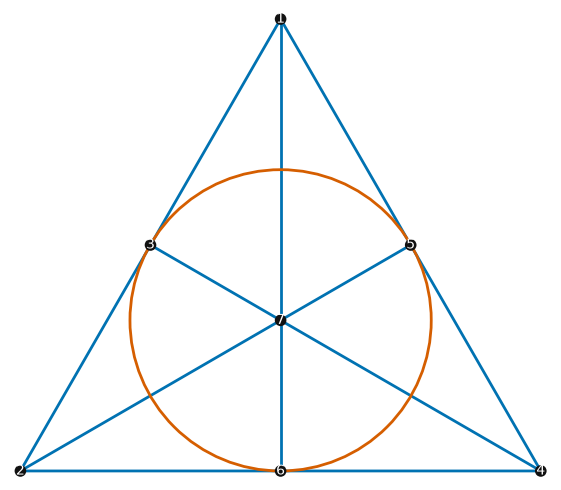

In [2]:
positions = {1: (0, 2.2), 2: (-1.9, -1.1), 4: (1.9, -1.1),
             6: (0, -1.1), 5: (0.95, 0.55), 3: (-0.95, 0.55), 7: (0, 0)}
picture = line([positions[1], positions[2], positions[4], positions[1]], color='#0072B2', thickness=2)
picture += line([positions[1], positions[6]], color='#0072B2', thickness=2)
picture += line([positions[2], positions[5]], color='#0072B2', thickness=2)
picture += line([positions[4], positions[3]], color='#0072B2', thickness=2)
picture += circle((0, 0), 1.1, color='#D55E00', thickness=2)
for label, xy in positions.items():
    picture += point(xy, size=70, color='#111111', zorder=5) + text(str(label), xy, color='white', fontsize=10, zorder=6)
picture.show(axes=False, aspect_ratio=1, figsize=[6, 5])

**讀圖。**  
每條畫出的曲線都包含 $3$ 個點。  
任兩點位於這 $7$ 條曲線中的一條上，而任兩條曲線交於這 $7$ 個點中的一點。

In [3]:
from itertools import combinations

point_pairs = {pair: 0 for pair in combinations(range(1, 8), 2)}
for block in fano_blocks:
    for pair in combinations(block, 2):
        point_pairs[tuple(sorted(pair))] += 1
print(set(point_pairs.values()))
print('每一對點恰好出現一次：', all(v == 1 for v in point_pairs.values()))

{1}
每一對點恰好出現一次： True


### 計數定理

**定理。** 每個有限射影平面都有一個整數 order $n \ge 2$，使得：
- 每條直線包含 $n + 1$ 個點；
- 每個點位於 $n + 1$ 條直線上；
- 點與直線都各有 $n^2 + n + 1$ 個。

**第一步：直線與 pencil 的大小相同。**  
設點 $P$ 不在直線 $\ell$ 上。  
每條通過 $P$ 的直線都與 $\ell$ 相交一次，而 $\ell$ 上的每個點都決定一條通過 $P$ 的直線。  
因此
$$\#\{\text{通過 }P\text{ 的直線}\} = \#\{\ell\text{ 上的點}\}.$$

**第二步：所有直線的大小相同。**  
給定直線 $\ell$ 與 $m$，nondegeneracy axiom 保證有一點 $P$ 不在其中任何一條上。  
第一步把每條直線與通過 $P$ 的 pencil 比較，所以 $|\ell| = |m|$。  
把這個共同的數量記為 $n + 1$；由 duality，每個點也位於 $n + 1$ 條直線上。

**第三步：從一點 $P$ 出發數完所有點。**  
通過 $P$ 的直線共有 $n + 1$ 條。  
除去 $P$ 後，這些直線互不相交，而且每條各貢獻 $n$ 個點。  
所以
$$v = 1 + (n + 1)n = n^2 + n + 1.$$
由 duality，直線也有同樣多條。

另一個常用的計數，是滿足 $P \in \ell$ 的 incidences $(P, \ell)$ 數量：
$$I = (n^2 + n + 1)(n + 1).$$
按照點或按照直線來數，都會得到同一個式子。

| Order $n$ | 點數 | 每條直線上的點數 | Incidences |
|---:|---:|---:|---:|
| $2$ | $7$ | $3$ | $21$ |
| $3$ | $13$ | $4$ | $52$ |
| $4$ | $21$ | $5$ | $105$ |
| $7$ | $57$ | $8$ | $456$ |

Order $7$ 的完整 projective-plane design 有 $57$ 個圖案與 $57$ 張卡片，每張卡片有 $8$ 個圖案。  
市售的 *Spot It!* 牌組採用這個設計，但只收錄其中 $55$ 張卡片。

### 有限體上的座標

設 $q$ 是 prime power，而 $\mathbb F_q$ 是有 $q$ 個元素的有限體。  
$\operatorname{PG}(2, q)$ 的一個點是非零 triple $(x, y, z)$，其中非零 scalar multiples 代表同一點：
$$(x, y, z) \sim (\lambda x, \lambda y, \lambda z),\qquad \lambda \in \mathbb F_q^{\times}.$$

非零 triples 共有 $q^3 - 1$ 個。  
每個 equivalence class 包含 $q - 1$ 個非零 scalar multiples，所以
$$\frac{q^3 - 1}{q - 1} = q^2 + q + 1$$
個 projective points。

一條直線由非零 triple $[a, b, c]$ 表示，同樣把非零 scalar multiples 視為相同。  
點 $(x, y, z)$ 位於這條直線上的條件是
$$ax + by + cz = 0.$$
無論把哪一個 triple rescale，這個方程式都不會改變。

這正是 inner-product picture；更精確地說，是 vector–covector pairing。  
這裡真正的 vector space 是 $\mathbb F_3^3$。非零向量 $p = (x, y, z)$ 張成
$$\operatorname{span}_{\mathbb F_3}(p)
= \{\lambda p : \lambda \in \mathbb F_3\}
= \{0, p, 2p\}.$$
其中兩個非零 representatives $p$ 與 $2p$ 代表同一個 projective point。

![射影點、射影直線與 pairing 的三維示意圖](projective-duality-3d.svg)

Covector $n = (a, b, c)$ 的 kernel
$$H_n = \{v \in \mathbb F_3^3 : n^{\mathsf T}v = 0\}$$
是 $2$-dimensional $\mathbb F_3$-subspace，並代表 projective line $[a, b, c]$。  
因此 $p$ 位於 $[a, b, c]$ 上，正好等價於 $n^{\mathsf T}p = ax + by + cz = 0$。

下面取 $n = (1, 1, 1)$ 與 $p = (1, -1, 0)$，所以 $n^{\mathsf T}p = 0$。  
為了畫出連續平面，Sage 將同一個方程式放到 $\mathbb R^3$ 中視覺化；真正的 set 仍是上面的 $\mathbb F_3$-subspace。  
執行下一個 cell 後，可以用滑鼠拖曳、旋轉這個 $3$D picture。

In [ ]:
s, t = var('s t')
plane = parametric_plot3d((s + t, -s, -t), (s, -1.5, 1.5), (t, -1.5, 1.5), color='#8ecae6', opacity=0.55)
normal = arrow3d((0, 0, 0), (1.2, 1.2, 1.2), color='#e76f51', width=5)
point_subspace = line3d([(-1.5, 1.5, 0), (1.5, -1.5, 0)], color='#6d28d9', thickness=6)
marked_point = point3d((1, -1, 0), color='#6d28d9', size=35)
labels = text3d('n = (1,1,1)', (1.3, 1.3, 1.3), color='#b43f29')
labels += text3d('p = (1,-1,0)', (1.05, -1.05, 0.08), color='#4c1d95')
show(plane + normal + point_subspace + marked_point + labels, frame=True, axes=True, aspect_ratio=1)

兩個相異點 $p$ 與 $r$ 決定直線 $p \times r$。  
對偶地，兩條相異直線的交點，是其 coefficient triples 的 cross product：
$$
(x_1, y_1, z_1) \times (x_2, y_2, z_2)
= (y_1z_2 - z_1y_2, z_1x_2 - x_1z_2, x_1y_2 - y_1x_2).
$$

熟悉的 cross-product 公式是 polynomial，所以在任何 field 上都有意義。  
它與輸入的兩個 triples 都 orthogonal。  
它非零，恰好等價於兩個 projective points 相異。

In [4]:
def normalize_projective(v, q):
    v = tuple(int(a) % q for a in v)
    first = next(a for a in v if a != 0)
    inverse = pow(first, -1, q)
    return tuple((inverse*a) % q for a in v)

def projective_points_prime(q):
    triples = ((x, y, z) for x in range(q) for y in range(q) for z in range(q) if (x, y, z) != (0, 0, 0))
    return sorted({normalize_projective(v, q) for v in triples})

In [5]:
for q in [2, 3, 5, 7]:
    points = projective_points_prime(q)
    print(f'q = {q}：{len(points)} 個點；預期為 {q^2 + q + 1}')

q = 2：7 個點；預期為 7
q = 3：13 個點；預期為 13
q = 5：31 個點；預期為 31
q = 7：57 個點；預期為 57


上面的程式把 triple 的第一個非零 coordinate 調整成 $1$，以此完成 normalization。  
這段程式只處理 prime $q$；Sage 的有限體也能處理 $q = p^k$。  
計算結果與 $q^2 + q + 1$ 相符。

### 有限域的存在與唯一性（難）

#### 在 extension field 中加入根

若域 $K$ 包含域 $E$，且在 $E$ 上使用相同的運算，  
就稱 $K$ 是 $E$ 的 **extension field（擴張域）** 。  

前面商域的 Bézout 證明適用於任意域 $E$：若 $g(t) \in E[t]$ 是不可約多項式，則
$$E[t]/(g(t))$$
是一個域，並且包含一份 $E$（那些只有常數的多項式）。

把 $t$ 的餘數類記為 $\alpha$，就得到 $g(\alpha) = 0$。  
因此，取商域可以把不可約多項式的一個根加入原來的域。

任意正次數多項式都有不可約因子：若它可約，就繼續分解，因子的次數逐次降低。  
給定 $h(x) \in E[x]$，取它的一個不可約因子，利用商域取得根 $\alpha$，再除去因子 $x - \alpha$。  
對剩下的多項式重複這個程序。

每次除去一個一次因子，剩餘次數就減少 $1$，所以有限次之後一定能完全分解。  
得到的擴張域 $K$ 由加入的根生成，稱為 $h$ 在 $E$ 上的 **splitting field（分裂域）** 。  
分裂的意思是 $h$ 會完全分裂成一次式，但又不要包山包海。  
所以它會式同時包含 $E$ 與 $h$ 全部根的域中最小的那個。  
若 $E$ 有限，每次加入根都只是做出有限維度的向量空間，所以做若干次之後 $K$ 還是有限。

![黑板筆記：加入平方根、立方根與 extension field 中的運算](finite-field-extension.jpeg)

#### 存在性：$x^{p^m} - x$ 的根形成域

固定質數 $p$ 與正整數 $m$，令 $q = p^m$，考慮
$$h(x) = x^q - x \in \mathbb F_p[x].$$
利用剛才的程序，取得它的一個分裂域 $K$。  
在 $K[x]$ 中，$h$ 可以分解成 $q$ 個一次因子的乘積。

接下來證明這些根都不同，且全部根在 $K$ 的運算下形成一個域。

對域上的多項式，定義 **formal derivative（形式導數）** ：
$$\left(\sum_{j = 0}^d c_j x^j\right)'
= \sum_{j = 1}^d j c_j x^{j - 1}.$$
由展開可以驗證乘法法則 $(uv)' = u'v + uv'$。  
若 $a$ 是重根，則 $h(x) = (x - a)^2v(x)$；對這個分解微分，就得到 $h'(a) = 0$。

因為 $K$ 的 characteristic 是 $p$，而 $p$ 整除 $q$，
$$h'(x) = qx^{q - 1} - 1 = -1.$$
所以 $h$ 沒有重根；它在 $K$ 中恰好有 $q$ 個不同的根。

在 characteristic 為 $p$ 的域中，$p$ 整除 $\binom pj$，其中 $0 < j < p$。  
二項式定理因此給出
$$(a + b)^p = a^p + b^p.$$
連續取 $m$ 次 $p$ 次方，便得到
$$(a + b)^q = a^q + b^q.$$
這個等式也保留加法反元素，所以 $(a - b)^q = a^q - b^q$。  
乘法則直接滿足 $(ab)^q = a^q b^q$。

令 $S$ 是 $h$ 在 $K$ 中的全部根：
$$S = \{a \in K : a^q = a\},\qquad |S| = q.$$
首先 $0, 1 \in S$。若 $a, b \in S$，則
$$(a - b)^q = a^q - b^q = a - b,$$
$$(ab)^q = a^q b^q = ab.$$
因此 $S$ 對減法與乘法封閉。  
對減法封閉也給出 $-a = 0 - a \in S$，以及 $a + b = a - (-b) \in S$。

若 $a \in S$ 且 $a \ne 0$，它在 $K$ 中的反元素滿足
$$(a^{-1})^q = (a^q)^{-1} = a^{-1}.$$
所以 $a^{-1}$ 也在 $S$ 中。

結合前面的封閉性，$S$ 繼承 $K$ 的域運算，且恰好有 $q = p^m$ 個元素。  
這就證明了每個質數冪大小的有限域都存在。

![黑板筆記：加入多項式的根與 x^q − x 的根的封閉性](finite-field-roots.jpeg)

#### 每個 $q$-域都包含 $x^q - x$ 的全部根

反過來，令 $F$ 是任意一個有 $q$ 個元素的域。  
固定 $a \ne 0$，乘上 $a$ 會重新排列 $F$ 的全部非零元素。  
令 $P$ 是所有非零元素的乘積，則 $P \ne 0$，而
$$P = \prod_{u \in F^\times}(au)
= a^{q - 1}\prod_{u \in F^\times}u
= a^{q - 1}P.$$
消去 $P$，得到 $a^{q - 1} = 1$。  
因此 $a^q = a$ 對每個 $a \in F$ 都成立，包含 $a = 0$。

所以 $F$ 的 $q$ 個元素都是 $x^q - x$ 的根，且
$$x^q - x = \prod_{a \in F}(x - a).$$
兩側都是 monic、次數為 $q$ 的多項式，右側列出左側的全部根。

因此，任意 $q$-域都是 $x^q - x$ 在其 prime subfield 上的一個分裂域。  
為了證明這些域同構，我們接下來說明如何把根的對應延伸成域的同構。

#### Minimal polynomial 與加入根後的域

若 $\alpha$ 在某個擴張域中，且某個非零的 $E$ 係數多項式在 $\alpha$ 取值為零，  
就稱 $\alpha$ 在 $E$ 上是 **algebraic（代數的）** 。  
（代表 $\alpha$ 扮演的角色不是 $\pi, e$ 那種東西，更像是 $\sqrt2, \varphi$）

選擇滿足 $f(\alpha) = 0$、次數最小的 monic polynomial $f \in E[x]$，  
稱為 $\alpha$ 在 $E$ 上的 **minimal polynomial（最小多項式）** 。  
它必定不可約：若 $f = uv$ 且兩個因子次數都較小，  
由 $u(\alpha)v(\alpha) = 0$ 可知其中一個在 $\alpha$ 為零，與最小性矛盾。

將任意 $g \in E[x]$ 除以 $f$，寫成
$$g = vf + r,\qquad r = 0\text{ 或 }\deg r < \deg f.$$
若 $g(\alpha) = 0$，則 $r(\alpha) = 0$；由 $f$ 的最小性，必有 $r = 0$。  
因此
$$g(\alpha) = 0\quad\Longleftrightarrow\quad f \mid g.$$
這也保證 minimal polynomial 唯一：兩個 monic 最小多項式必定互相整除。

令 $E(\alpha)$ 表示包含 $E$ 與 $\alpha$ 的最小子域。  
代入 $\alpha$ 給出對應
$$E[x]/(f(x)) \longrightarrow E(\alpha),\qquad [g(x)] \longmapsto g(\alpha).$$
剛才的整除條件保證這個對應是明確且一一的，並保留加法與乘法。  
左側是域，所以其像也是域；它包含 $E$ 與 $\alpha$，因此像恰好是 $E(\alpha)$。

所以
$$\boxed{E(\alpha) \cong E[x]/(f(x)).}$$

#### 同構可以沿著根的對應延伸

假設已有域同構 $\phi : E \longrightarrow E'$，且 $\alpha$ 在 $E$ 上的 minimal polynomial 是 $f$。  
把 $f$ 的每個係數套用 $\phi$，得到 $\widetilde f \in E'[x]$。  
它在 $E'$ 上不可約，因為任何分解都能經 $\phi^{-1}$ 還原成 $f$ 的分解。

若 $\beta$ 是 $\widetilde f$ 在某個擴張域中的根，它在 $E'$ 上的 minimal polynomial 就是 $\widetilde f$。  
對每個 $g \in E[x]$，同樣把係數套用 $\phi$，記結果為 $\widetilde g$。

商域的表示給出域同構
$$\Phi : E(\alpha) \longrightarrow E'(\beta),\qquad
g(\alpha) \longmapsto \widetilde g(\beta).$$
若兩個 $g$ 在 $\alpha$ 的值相同，它們的差被 $f$ 整除；  
係數映射後的差就被 $\widetilde f$ 整除，因此在 $\beta$ 的值也相同。  
反方向用 $\phi^{-1}$ 做相同的構造，所以 $\Phi$ 有逆映射。

這個同構滿足 $\Phi|_E = \phi$，且 $\Phi(\alpha) = \beta$。  
也就是既有的同構可以延伸到加入根後的域。

#### 唯一性：逐一把根對應起來

令 $F$ 與 $F'$ 都有 $q = p^m$ 個元素。  
由前面的質數冪論證，兩者的 characteristic 都是 $p$。  
先把兩者的 prime subfields 按 $a \cdot 1 \mapsto a \cdot 1$ 對應，記為 $\phi_0$。

列出 $F$ 的全部元素 $\alpha_1, \ldots, \alpha_q$，並依序加入：
$$E_0 = \mathbb F_p,\qquad E_i = E_{i - 1}(\alpha_i),\qquad E_q = F.$$
我們逐步把 $\phi_0$ 延伸成 $E_i$ 到 $F'$ 的某個子域的同構。

假設已經有 $\phi_{i - 1} : E_{i - 1} \longrightarrow E'_{i - 1} \subseteq F'$。  
令 $f_i$ 是 $\alpha_i$ 在 $E_{i - 1}$ 上的 minimal polynomial。  
因為 $\alpha_i^q = \alpha_i$，前面的整除條件給出
$$f_i(x) \mid x^q - x.$$
把係數經 $\phi_{i - 1}$ 映射，得到 $\widetilde f_i$。  
這個同構在 prime subfield 上保持原來的對應，所以 $x^q - x$ 的係數保持不變，仍有
$$\widetilde f_i(x) \mid x^q - x.$$

$x^q - x$ 在 $F'$ 中完全分解，因此其正次數因子 $\widetilde f_i$ 在 $F'$ 中有一個根 $\beta_i$。  
利用剛才的同構延伸方法，得到
$$\phi_i : E_i = E_{i - 1}(\alpha_i)
\longrightarrow E'_{i - 1}(\beta_i) \subseteq F'.$$
它延伸 $\phi_{i - 1}$，並將 $\alpha_i$ 對應到 $\beta_i$。

重複有限次，最後得到一個保留加法與乘法的一一映射 $\phi_q : F \longrightarrow F'$。  
兩邊都只有 $q$ 個元素，所以它也映射到 $F'$ 的全部元素，因而 $F \cong F'$。

結合存在性與唯一性，對每個質數 $p$ 與正整數 $m$，
$$\boxed{\text{存在一個含有 }p^m\text{ 個元素的域，且在同構意義下唯一。}}$$
因此記號 $\mathbb F_{p^m}$ 表示這個同構類；選擇不同的建構，得到的運算可以透過同構互相對應。

分裂域與有限域分類的延伸閱讀：  
[Kopparty, Introduction to finite fields（§1.5–1.7）](https://www.math.toronto.edu/swastik/courses/finitefields-F23/intro.pdf)。

### Binary 表示的 Fano plane

在 $\mathbb F_2$ 上沒有 nontrivial rescaling。  
因此 $7$ 個 projective points 就是 $7$ 個非零 binary triples。  
三個相異點 $u, v, w$ 共線，恰好等價於
$$u + v + w = 000,$$
也就是 $u \mathbin{\mathrm{XOR}} v = w$。

In [6]:
binary_points = [tuple(map(int, f'{k:03b}')) for k in range(1, 8)]
binary_lines = []
for u, v in combinations(binary_points, 2):
    w = tuple(a ^^ b for a, b in zip(u, v))
    block = tuple(sorted([u, v, w]))
    if block not in binary_lines:
        binary_lines.append(block)
for block in sorted(binary_lines):
    print('  '.join(''.join(map(str, v)) for v in block))

001  010  011
001  100  101
001  110  111
010  100  110
010  101  111
011  100  111
011  101  110


在 Sage 語法中，bitwise XOR 寫成 `^^`，因為 `^` 代表 exponentiation。  
例如，直線 $x = 0$ 由 $001$、$010$ 與 $011$ 組成。  
第二講還會再用到這個 XOR 描述。

### 例子：$\operatorname{PG}(2, 3)$ 中的一條直線

求通過以下兩點的直線：
$$P = (1, 1, 0),\qquad Q = (0, 1, 2).$$
它們的 cross product 是
$$P \times Q = (2, -2, 1) = (2, 1, 1) \pmod 3.$$
所以直線方程式是 $2x + y + z = 0$。

In [7]:
points_3 = projective_points_prime(3)
line_vector = (2, 1, 1)
points_on_line = [p for p in points_3 if sum(a*b for a, b in zip(line_vector, p)) % 3 == 0]
print(points_on_line)
print('直線上的點數：', len(points_on_line))
print('平面中的點數：', len(points_3))

[(0, 1, 2), (1, 0, 1), (1, 1, 0), (1, 2, 2)]
直線上的點數： 4
平面中的點數： 13


這 $4$ 個點是
$$(1, 0, 1),\quad (1, 1, 0),\quad (1, 2, 2),\quad (0, 1, 2).$$
這與 $q + 1 = 4$ 相符，而整個平面共有 $q^2 + q + 1 = 13$ 個點。

### Incidence matrix

每條直線對應一個 row，每個點對應一個 column。  
在 **incidence matrix** $M$ 中，若 $P \in \ell$，則 $M_{\ell P} = 1$，否則為 $0$。  
在 order $n$ 的平面中，每個 row 與 column 都有 $n + 1$ 個 $1$，而任兩個相異 rows 恰好在一個 column 中同時為 $1$。

這些事實可以濃縮成一個 matrix identity：
$$MM^{\mathsf T} = nI + J,$$
其中 $I$ 是 identity matrix，$J$ 是 all-ones matrix。  
Diagonal entries 是 $n + 1$，off-diagonal entries 則是 $1$。

Fano plane 的 incidence matrix 是
$$
M = \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0 \\
1 & 0 & 0 & 1 & 1 & 0 & 0 \\
1 & 0 & 0 & 0 & 0 & 1 & 1 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 \\
0 & 1 & 0 & 0 & 1 & 0 & 1 \\
0 & 0 & 1 & 1 & 0 & 0 & 1 \\
0 & 0 & 1 & 0 & 1 & 1 & 0
\end{pmatrix}.
$$

它的 Gram matrix 是
$$
MM^{\mathsf T} = \begin{pmatrix}
3 & 1 & 1 & 1 & 1 & 1 & 1 \\
1 & 3 & 1 & 1 & 1 & 1 & 1 \\
1 & 1 & 3 & 1 & 1 & 1 & 1 \\
1 & 1 & 1 & 3 & 1 & 1 & 1 \\
1 & 1 & 1 & 1 & 3 & 1 & 1 \\
1 & 1 & 1 & 1 & 1 & 3 & 1 \\
1 & 1 & 1 & 1 & 1 & 1 & 3
\end{pmatrix} = 2I + J.
$$

In [8]:
M = matrix(ZZ, [[1 if p in block else 0 for p in range(1, 8)] for block in fano_blocks])
print('MM^T = 2I + J:', M*M.transpose() == 2*identity_matrix(7) + ones_matrix(7))

MM^T = 2I + J: True


## 第一講習題

標記 ★ 的題目是共同核心；★★ 需要多一個想法；★★★ 是延伸題。  
需要時一次只看一個提示。

### 問題 1：委員會 ★

某社團有 $7$ 名社員。  
每個委員會恰有 $3$ 名社員，而且任兩名社員恰好共同參加一個委員會。
1. 一共有多少個委員會？每名社員參加多少個委員會？
2. 證明任兩個委員會恰好共有一名社員。

<details><summary>提示</summary>用兩種方法計算社員 pair 的數量。接著固定一個委員會，數所有與它相交的其他委員會。</details>

<details><summary>解答概要</summary>社員 pairs 共有 $\binom72 = 21$ 對，而每個委員會包含 $\binom32 = 3$ 對，所以共有 $7$ 個委員會。每名社員有 $6$ 名搭檔，每個委員會提供 $2$ 名，因此每人參加 $3$ 個委員會。任兩個委員會至多共有一人。固定一個委員會後，其中 $3$ 人各自還參加另外 $2$ 個委員會，得到 $6$ 個相異的委員會，正好是其餘所有委員會；所以每個都與固定的委員會恰好相交一次。</details>

### 問題 2：座標 ★

在 $\operatorname{PG}(2, 3)$ 中，求通過 $(1, 1, 0)$ 與 $(0, 1, 2)$ 的直線。  
列出直線上的所有點，並確認共有 $4$ 個。  
整個平面共有多少個點？

<details><summary>提示</summary>先取 cross product，再 modulo $3$ 化簡，最後 normalize 所得方程式的每個非零解。</details>

<details><summary>解答概要</summary>Cross product modulo $3$ 是 $(2, 1, 1)$，所以直線為 $2x + y + z = 0$。其 normalized points 是 $(1, 0, 1)$、$(1, 1, 0)$、$(1, 2, 2)$ 與 $(0, 1, 2)$。整個平面共有 $3^2 + 3 + 1 = 13$ 個點。</details>

### 問題 3：Spot It ★★

牌組中的每張卡片都有 $k$ 個圖案，而且任兩張卡片恰好共有一個圖案。
1. 證明牌組可以有無限多張卡片。
2. 若沒有任何圖案出現在每張卡片上，證明卡片至多有 $k^2 - k + 1$ 張。
3. 當 $k = 3$ 時，給出達到此 bound 的牌組。

<details><summary>提示</summary>第 2 小題先證明每個圖案至多出現在 $k$ 張卡片上。接著固定一張卡片，按照與它相交的圖案計算其他卡片。</details>

<details><summary>解答概要</summary>第 1 小題，在每張卡片上放一個共同圖案，再各自加入 $k - 1$ 個專屬圖案。第 2 小題，若圖案 $x$ 出現在 $k + 1$ 張卡片上，移除 $x$ 後，這些卡片的圖案集合兩兩不交；任何不含 $x$ 的卡片至少需要 $k + 1$ 個圖案，才能與它們全部相交。因此每個圖案至多出現在 $k$ 張卡片上。固定一張卡片後，它的每個圖案至多再連到 $k - 1$ 張卡片，所以總數至多為 $1 + k(k - 1)$。當 $k = 3$ 時，$7$ 個 Fano triples 達到此 bound。</details>

### 問題 4：不含矩形的方格 ★★

在一個 $7 \times 7$ 方格中，把部分 cells 塗色。  
任意 $4$ 個塗色 cells 都不能成為邊平行於格線的矩形四個頂點。  
最多可以塗多少個 cells？

<details><summary>提示</summary>若第 $i$ 個 row 有 $r_i$ 個塗色 cells，計算各 rows 選出的 column pairs。構造部分使用 Fano incidence matrix。</details>

<details><summary>解答概要</summary>每對 columns 至多在一個 row 中同時被選，所以 $\sum_i \binom{r_i}{2} \le \binom72 = 21$。若有 $22$ 個塗色 cells，由 convexity，左式最小也有 $6\binom32 + \binom42 = 24$，矛盾。Fano incidence matrix 有 $21$ 個 $1$，且沒有 $2 \times 2$ 的 all-one submatrix，所以最大值是 $21$。</details>

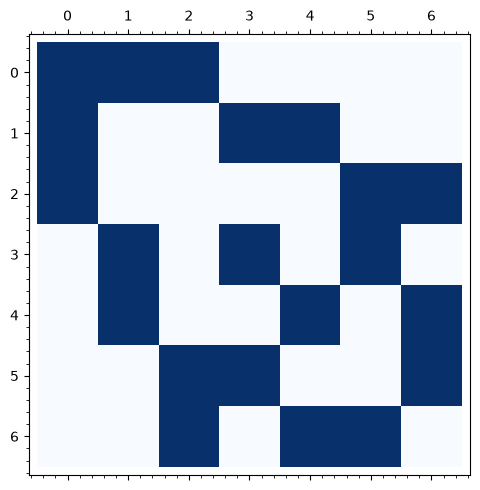

In [9]:
grid_plot = matrix_plot(M, cmap='Blues', colorbar=False)
grid_plot.show(figsize=[5, 5], axes=False)

Rows 代表 Fano lines，columns 代表 Fano points。  
若出現矩形，就表示兩條直線共有兩個點，與射影平面公理矛盾。

### 問題 5：Arcs ★★★

在 order $n$ 的射影平面中，設 $S$ 是任三點都不共線的點集。
1. 證明 $|S| \le n + 2$。
2. 若 $n$ 是奇數，證明更強的 bound $|S| \le n + 1$。

<details><summary>提示</summary>固定 $P \in S$，觀察通過它的 $n + 1$ 條直線。若第一個 bound 取等號，先判斷每條直線如何與 $S$ 相交，再從 $S$ 外的一點開始計數。</details>

<details><summary>解答概要</summary>$S$ 中除 $P$ 外的點，分別位於通過 $P$ 的不同直線上，所以 $|S| - 1 \le n + 1$。若 $|S| = n + 2$，通過 $S$ 中任一點的每條直線都還會再遇到 $S$ 一次，因此每條直線與 $S$ 相交於 $0$ 或 $2$ 點。從 $Q \notin S$ 出發，通過 $Q$ 的 $n + 1$ 條直線把 $S$ 分成 pairs。因此 $n + 2$ 是偶數，故 $n$ 是偶數。當 $n$ 為奇數時不可能取等號。</details>

## 兩講之間的作業

前兩題會在第二講再次出現。  
第三題比較有限射影幾何與普通實平面。  
第四題預告射影平面與 Latin squares 的關係。

### H1：不含 $4$-cycles 的圖 ★★

一個 graph 有 $N$ 個 vertices，而且不含長度為 $4$ 的 cycle。  
證明其 edges 數量滿足
$$e \le \frac N4\left(1 + \sqrt{4N - 3}\right).$$
**提示。** 計算通過各 vertex、長度為 $2$ 的 paths。

### H2：更大的方格 ★★

設 $N = q^2 + q + 1$。  
證明一個不含矩形的 $N \times N$ 方格至多有 $(q + 1)N$ 個塗色 cells。  
使用 $\operatorname{PG}(2, 3)$，在 $13 \times 13$ 方格中塗出 $52$ 個 cells。

### H3：Sylvester–Gallai theorem ★★★

在普通實平面中，給定一個不全共線的有限點集。證明存在一條直線恰好通過其中兩點。  
進一步推出 Fano plane 無法只用普通直線畫出。  
**提示。** 考慮所有「點 $P$ 與通過另外兩點的直線」所成的 pairs，選擇正距離最小的一對。

### H4：Latin squares ★

Order $n$ 的 **Latin square** 是填入 $0, 1, \ldots, n - 1$ 的 $n \times n$ 方格，每個數在每個 row 與 column 中各出現一次。  
若疊合兩個 Latin squares 後，每個 ordered pair 恰好出現一次，就稱它們 **orthogonal** 。  
找出兩個互相 orthogonal、order $3$ 的 Latin squares，並試試 order $2$。

## 第二講：把線性代數當作組合學武器

第一講用幾何編碼 incidence。  
現在把 subset 變成 vector、symmetric difference 變成加法、交集的 parity 變成 dot product。  
Dimension 會把局部的 parity 條件變成全域的 bounds。

### 作業回顧：$C_4$ bound

在不含 $C_4$ 的 graph 中，任兩個 vertices 至多有一個共同 neighbor。  
等價地，任一對 endpoints 之間至多有一條長度為 $2$ 的 path。  
因此
$$\sum_v \binom{d(v)}2 \le \binom N2.$$

設 $d = 2e/N$ 是 average degree。  
由 convexity，$N\binom d2 \le \sum_v \binom{d(v)}2$，因此
$$d(d - 1) \le N - 1.$$
解這個 quadratic inequality，再使用 $e = Nd/2$，得到
$$e \le \frac N4\left(1 + \sqrt{4N - 3}\right).$$

### 把 subsets 當作 binary vectors

對 subset $A \subseteq [n]$，定義其 incidence vector $v_A \in \mathbb F_2^n$：
$$(v_A)_i = \begin{cases}1,& i \in A,\\0,& i \notin A.\end{cases}$$
所有運算都 modulo $2$，所以 $1 + 1 = 0$。

| 集合 | $\mathbb F_2$ 上的 vectors |
|---|---|
| 子集合 $A \subseteq [n]$ | Incidence vector $v_A$ |
| 對稱差 $A \mathbin{\triangle} B$ | 和 $v_A + v_B$ |
| $|A \cap B|$ 的 parity | Dot product $v_A \cdot v_B$ |
| $|A|$ 的 parity | Self-dot-product $v_A \cdot v_A$ |

例如，在 universe $[6]$ 中，設 $A = \{1, 3, 4\}$、$B = \{2, 3, 4, 6\}$。  
則
$$v_A = 101100,\qquad v_B = 011101,\qquad v_A + v_B = 110001.$$
因為 $|A \cap B| = 2$ 是偶數，所以 dot product 是 $0$。

### 三個線性代數事實

1. $\mathbb F_2^n$ 中超過 $n$ 個 vectors 必定 linearly dependent。
2. 若 $v_i \cdot v_i = 1$，且當 $i \ne j$ 時 $v_i \cdot v_j = 0$，則 $v_1, \ldots, v_m$ independent。
3. 對 subspace $W \le \mathbb F_2^n$，
$$\dim W + \dim W^\perp = n.$$

為了證明第二點，假設 $c_1v_1 + \cdots + c_mv_m = 0$。  
兩邊與 $v_j$ 做 dot product。  
所有 cross terms 都消失，只剩 $c_j(v_j \cdot v_j) = c_j = 0$。  
這對每個 $j$ 都成立，所以原來的 relation 只能是 trivial relation。

Orthogonal complement 定義為
$$W^\perp = \{x \in \mathbb F_2^n : x \cdot w = 0\text{ 對所有 }w \in W\}.$$
與 Euclidean geometry 不同，$W$ 與 $W^\perp$ 可能重疊。  
不過整個空間上的 dot product 是 nondegenerate，所以 dimension formula 仍然成立。

### Oddtown

一座城鎮有 $n$ 名居民。  
每個 club 的人數都是奇數，而任兩個相異 clubs 的共同成員數都是偶數。  
證明 clubs 至多有 $n$ 個。

令 $v_i$ 是第 $i$ 個 club 的 incidence vector。  
題目的條件變成
$$v_i \cdot v_i = 1,\qquad v_i \cdot v_j = 0\quad(i \ne j).$$
由第二個事實，這些 club vectors 在 $\mathbb F_2^n$ 中 independent。  
因此至多有 $n$ 個。

等號確實可以成立：取 $n$ 個各自只有一人的 clubs。  
這個證明很短，因為題目的組合條件在 $\mathbb F_2$ 上形成 identity Gram matrix。

### Eventown

現在每個 club 的大小都是偶數，任兩個 clubs 的交集大小也是偶數，而且沒有兩個 clubs 完全相同。
1. 構造 $2^{\lfloor n/2\rfloor}$ 個 clubs。
2. 證明不可能有更多。

**構造。** 把居民配成 $\{1, 2\}, \{3, 4\}, \ldots$。  
取這些 disjoint pairs 的任意 union。  
共有 $2^{\lfloor n/2\rfloor}$ 種選法，而任兩個這樣的 unions，其交集仍是若干 pairs 的 union。

**Upper bound。** 令 $W$ 為所有 club vectors 的 span。  
任兩個 generators 都 orthogonal，也包含 generator 與自己，因此 $W \subseteq W^\perp$。  
所以
$$2\dim W \le \dim W + \dim W^\perp = n.$$
這些 clubs 是 $W$ 中相異的 vectors，所以至多有 $|W| \le 2^{\lfloor n/2\rfloor}$ 個。

### Lights Out

在有限 graph 的每個 vertex 放一盞燈。  
按下一個 vertex，會 toggle 該處與所有相鄰 vertices 的燈。  
是否總能把全亮的 configuration 變成全暗？

同一個 vertex 按兩次沒有淨效果，因此 pressing pattern 是 vector $z \in \mathbb F_2^n$。  
若 $A$ 是 adjacency matrix，則 pressing pattern $z$ 所 toggle 的 vector 是
$$Mz,\qquad M = A + I.$$
我們需要解 $Mz = \boldsymbol 1$。

在 $3 \times 3$ 方格上，按下四個角與中心。  
四個角與中心各被 toggle 一次；每個邊的中點被 toggle 三次。  
因此每盞燈都被 toggle 奇數次。

In [10]:
G_grid = graphs.Grid2dGraph(3, 3)
vertices = sorted(G_grid.vertices())
A_grid = G_grid.adjacency_matrix(vertices=vertices).change_ring(GF(2))
M_grid = A_grid + identity_matrix(GF(2), 9)
press = vector(GF(2), [1 if v in [(0, 0), (0, 2), (1, 1), (2, 0), (2, 2)] else 0 for v in vertices])
print('按法：', press)
print('各燈被 toggle 的次數 parity：', M_grid*press)

按法： (1, 0, 1, 0, 1, 0, 1, 0, 1)
各燈被 toggle 的次數 parity： (1, 1, 1, 1, 1, 1, 1, 1, 1)


**定理。** 在每個有限 graph 上，都能把全亮的 configuration 變成全暗。  
因為 $M$ symmetric，它的 column space 是 $(\ker M)^\perp$。  
只要證明 $\boldsymbol 1$ 與每個 $x \in \ker M$ 都 orthogonal 即可。

若 $Mx = 0$，在 $\mathbb F_2$ 上展開 $x^{\mathsf T}Mx$。  
因為 $M$ symmetric，off-diagonal terms 成對出現並互相抵消。  
$M = A + I$ 的 diagonal entries 都是 $1$，而且 $x_i^2 = x_i$，所以
$$0 = x^{\mathsf T}Mx = \sum_i x_i = \boldsymbol 1 \cdot x.$$
因此 $\boldsymbol 1 \in (\ker M)^\perp = \operatorname{col}M$。

定理保證解存在，但不保證唯一。  
若 $z_0$ 是一個解，則每個解都能寫成 $z_0 + x$，其中 $x \in \ker M$。  
因此恰好有 $2^{\dim\ker M}$ 個成功的 pressing patterns。

In [11]:
def lights_out_solution(graph):
    verts = sorted(graph.vertices())
    A = graph.adjacency_matrix(vertices=verts).change_ring(GF(2))
    M = A + identity_matrix(GF(2), len(verts))
    one = vector(GF(2), [1]*len(verts))
    return verts, M.solve_right(one), M.right_kernel().dimension()

examples = [('路徑圖 P_8', graphs.PathGraph(8)),
            ('環圖 C_8', graphs.CycleGraph(8)),
            ('Petersen graph', graphs.PetersenGraph())]
for label, graph in examples:
    verts, solution, nullity = lights_out_solution(graph)
    print(label, '解 =', solution, 'nullity =', nullity)

路徑圖 P_8 解 = 

(1, 0, 0, 1, 0, 0, 1, 0) nullity = 1
環圖 C_8 解 = (1, 1, 1, 1, 1, 1, 1, 1) nullity = 0
Petersen graph 解 = (1, 1, 1, 1, 1, 0, 0, 0, 0, 0) nullity = 5


### Polarity graph（極性圖）

把 $\operatorname{PG}(2, q)$ 的點當作 vertices。  
當相異點 $x$ 與 $y$ 滿足
$$x \cdot y = 0.$$
時，就把它們連起來。這個 graph 把射影平面中的 incidence 轉換成 adjacency。

任兩個相異 vertices $x$ 與 $y$ 至多有一個共同 neighbor。  
事實上，共同 neighbor $z$ 滿足 $z \cdot x = z \cdot y = 0$，所以 projectively $z = x \times y$。  
若有 $4$-cycle，兩個相對的 vertices 就會有兩個共同 neighbors。  
因此 polarity graph 不含 $C_4$。

每個點都與某條 projective line 上的 $q + 1$ 個點 orthogonal。  
若 $x \cdot x = 0$，則 $x$ 自己也在那條直線上；但 graph 不允許 loops，所以它的 degree 是 $q$，不是 $q + 1$。  
對 standard dot product，恰有 $q + 1$ 個 projective points self-orthogonal。

所有 degrees 的和是
$$
(q + 1)(q^2 + q + 1) - (q + 1) = q(q + 1)^2.
$$
所以 polarity graph 有
$$e = \frac{q(q + 1)^2}{2}$$
條 edges。

In [12]:
def polarity_graph_prime(q):
    pts = projective_points_prime(q)
    graph = Graph()
    graph.add_vertices(pts)
    graph.add_edges((u, v) for u, v in combinations(pts, 2)
                    if sum(a*b for a, b in zip(u, v)) % q == 0)
    return graph

for q in [2, 3, 5, 7]:
    graph = polarity_graph_prime(q)
    print(f'q = {q}：|V| = {graph.order()}，|E| = {graph.size()}，girth = {graph.girth()}')

q = 2：|V| = 7，|E| = 9，girth = 3
q = 3：|V| = 13，|E| = 24，girth = 3
q = 5：|V| = 31，|E| = 90，girth = 3
q = 7：|V| = 57，|E| = 224，girth = 3


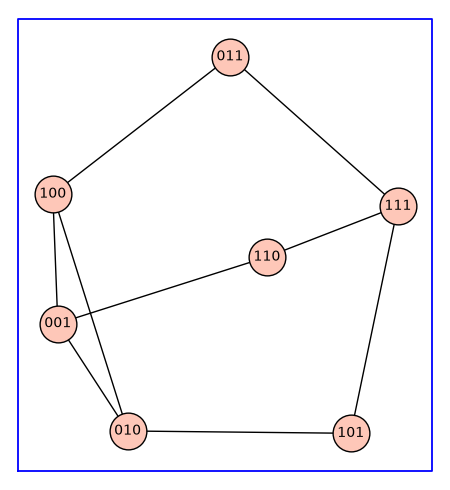

In [13]:
polarity_2 = polarity_graph_prime(2)
labels = {v: ''.join(map(str, v)) for v in polarity_2.vertices()}
polarity_2.plot(vertex_labels=labels, vertex_size=700, graph_border=True, figsize=[7, 5]).show()

當 $N = q^2 + q + 1$ 時，作業中的 bound 變成
$$\frac N4\left(1 + \sqrt{4N - 3}\right) = \frac{(q + 1)(q^2 + q + 1)}2.$$
Polarity graph 與這個 upper bound 只差 $(q + 1)/2$ 條 edges。  
因此有限幾何能產生幾乎 extremal 的 $C_4$-free graphs。

### Latin squares 與射影平面

Order $n$ 的射影平面存在，恰好等價於存在一組完整的 $n - 1$ 個兩兩 orthogonal、order $n$ 的 Latin squares。  
移除一條 projective line 會得到 affine plane。  
兩個 coordinate directions 成為 rows 與 columns；其餘每個 parallel class 記錄一個 Latin square。

當 $q$ 是 prime power 時，對每個非零 $a \in \mathbb F_q$ 定義
$$L_a(i, j) = ai + j.$$
每個 $L_a$ 都是 Latin。  
若 $a \ne b$，方程式 $ai + j = r$ 與 $bi + j = s$ 有唯一解 $(i, j)$，所以 $L_a$ 與 $L_b$ orthogonal。

In [14]:
def latin_square_prime(q, a):
    return matrix(ZZ, q, q, lambda i, j: (a*i + j) % q)

L1 = latin_square_prime(3, 1)
L2 = latin_square_prime(3, 2)
show(L1)
show(L2)
pairs = [(L1[i, j], L2[i, j]) for i in range(3) for j in range(3)]
print('每個 ordered pair 恰好出現一次：', len(set(pairs)) == 9)

[0 1 2]
[1 2 0]
[2 0 1]

[0 1 2]
[2 0 1]
[1 2 0]

每個 ordered pair 恰好出現一次： True


### 哪些 orders 存在？

每個 prime power 都是某個射影平面的 order。  
目前不知道任何 order 不是 prime power 的射影平面。  
**Prime-power conjecture** 猜想除此之外沒有別的可能，但現有方法距離解決它仍非常遙遠。

Bruck–Ryser theorem 給出一個必要的算術條件：若
$$n \equiv 1 \text{ 或 }2 \pmod 4$$
而且 order $n$ 的射影平面存在，則 $n$ 必須是兩個整數平方的和。  
這排除了 $6, 14, 21, 22$，以及無限多個其他 orders。

| Order | 狀態 | 理由 |
|---:|:---:|---|
| $6$ | 不存在 | Bruck–Ryser；也可由 Tarry 對 Latin squares 的枚舉得到 |
| $10$ | 不存在 | 1989 年完成的 computer-assisted search |
| $12$ | 未解 | Bruck–Ryser 無法排除 |
| $14$ | 不存在 | Bruck–Ryser |
| $15$ | 未解 | Bruck–Ryser 無法排除 |

Order $10$ 顯示了必要條件與存在性之間的差距：$10 = 1^2 + 3^2$ 通過 Bruck–Ryser test，但相應的平面並不存在。  
後來的研究以可獨立檢查的 SAT certificates 重新驗證了 1989 年的計算。  
截至 2026 年 10 月，order $12$ 仍是第一個未解的 order。

### Fisher inequality

一座城鎮有 $n$ 名居民與 $m$ 個相異 clubs。  
任兩個 clubs 恰好共有 $\lambda$ 名成員，其中 $\lambda \ge 1$。  
證明 $m \le n$。  
這次要在 $\mathbb R$ 上工作，而不是 $\mathbb F_2$。

令 $v_i \in \mathbb R^n$ 為 club vectors。  
至多有一個 club 的大小恰好是 $\lambda$：這樣的 club 會包含於每個其他 club。  
假設 $\sum_i c_iv_i = 0$。取 squared norm 得到
$$0 = \left|\sum_i c_iv_i\right|^2 = \lambda\left(\sum_i c_i\right)^2 + \sum_i c_i^2(|C_i| - \lambda).$$

右邊每一項都 nonnegative。  
因此對每個大小大於 $\lambda$ 的 club，都有 $c_i = 0$；若還剩下一個 coefficient，它也只能是 $0$。  
這些 club vectors 在 $\mathbb R^n$ 中 independent，所以 $m \le n$。  
這和 Oddtown 使用相同的想法，只是 field 與 Gram matrix 不同。

## 第二講習題

請使用方法，而不是背誦解答。
1. **Oddtown ★：** 不回頭看講義，重建 independence proof。
2. **Eventown ★★：** 說明為何 generators 兩兩 orthogonal，會推得整個 span 中的 vectors 兩兩 orthogonal。
3. **Lights Out ★／★★★：** 先解 $3 \times 3$ 棋盤，再對每個 graph 證明定理。
4. **Polarity graph ★★：** 證明它不含 $C_4$，並計算 edges 數量。
5. **Fisher ★★★：** 指出證明究竟在哪裡用到 $\mathbb R$ 上的 positivity。

## 總結

| 組合訊號 | 翻譯 | 工具 |
|---|---|---|
| 任兩個 objects 恰好相交一次 | Projective incidence | Double counting 與 duality |
| 任兩個 rows 不會共有兩個 columns | 不含矩形的 incidence matrix | Convexity |
| 交集的 parity | $\mathbb F_2$ 上的 dot product | Independence 與 orthogonal complements |
| Toggle operations | $\mathbb F_2$ 上的 linear system | Kernel–column-space orthogonality |
| 恰有 $\lambda$ 個共同成員 | $\mathbb R$ 上的 Gram matrix | Positivity 與 independence |

最重要的習慣是問：**哪個代數 object 能精確記錄題目的條件？**  
只要翻譯正確，看似困難的 extremal problem 可能就會變成 dimension count、matrix identity，或一次乾淨的 double count。

## 參考資料與延伸閱讀

- P. Dembowski, *Finite Geometries*, Springer, 1968.
- R. H. Bruck and H. J. Ryser, [“The nonexistence of certain finite projective planes”](https://doi.org/10.4153/CJM-1949-009-2), *Canadian Journal of Mathematics* 1 (1949), 88–93.
- C. W. H. Lam, L. Thiel, and S. Swiercz, [“The non-existence of finite projective planes of order 10”](https://doi.org/10.4153/CJM-1989-049-4), *Canadian Journal of Mathematics* 41 (1989), 1117–1123.
- B. Alexeev and D. G. Mixon, [“Forbidden Sidon subsets of perfect difference sets, featuring a human-assisted proof”](https://arxiv.org/abs/2510.19804), arXiv:2510.19804, 2026.
- P. Frankl and R. M. Wilson, “Intersection theorems with geometric consequences”, *Combinatorica* 1 (1981), 357–368.